# Computer Vision

Let's do some very basic computer vision. We're going to import the MNIST handwritten digits data and $k$NN to predict values (i.e. "see/read").

1. To load the data, run the following code in a chunk:
```
import pickle
with open('data/minst.pkl', 'rb') as f:
    data = pickle.load(f)
X_train, y_train = data['X_train'], data['y_train']
X_test, y_test = data['X_test'], data['y_test']
```
The `y_test` and `y_train` vectors, for each index `i`, tell you want number is written in the corresponding index in `X_train[i]` and `X_test[i]`. The value of `X_train[i]` and `X_test[i]`, however, is a 28$\times$28 array whose entries contain values between 0 and 256. Each element of the matrix is essentially a "pixel" and the matrix encodes a representation of a number. To visualize this, run the following code to see the first ten numbers:
```
import matplotlib.pyplot as plt
import numpy as np
np.set_printoptions(edgeitems=30, linewidth=100000)
for i in range(5): 
    print(y_test[i],'\n') # Print the label
    print(X_test[i],'\n') # Print the matrix of values
    plt.contourf(np.rot90(X_test[i].transpose())) # Make a contour plot of the matrix values
    plt.show()
```
OK, those are the data: Labels attached to handwritten digits encoded as a matrix.

2. What is the shape of `X_train` and `X_test`? What is the shape of `X_train[i]` and `X_test[i]` for each index `i`? What is the shape of `y_train` and `y_test`?
3. Use Numpy's `.reshape()` method to covert the training and testing data from a matrix into an vector of features. So, `X_test[index].reshape((1,784))` will convert the $index$-th element of `X_test` into a $28\times 28=784$-length row vector of values, rather than a matrix. Turn `X_train` into an $N \times 784$ matrix $X$ that is suitable for scikit-learn's kNN classifier where $N$ is the number of observations and $784=28*28$ (you could use, for example, a `for` loop).
4. Use the reshaped `X_test` and `y_test` data to create a $k$-nearest neighbor classifier of digit. What is the optimal number of neighbors $k$? If you can't determine this, play around with different values of $k$ for your classifier.
5. For the optimal number of neighbors, how well does your predictor perform on the test set? Report the accuracy, compute a confusion matrix, and explain your findings.
6. For your confusion matrix, which mistakes are most likely? Do you find any interesting patterns?
7. So, this is how computers "see." They convert an image into a matrix of values, that matrix becomes a vector in a dataset, and then we deploy ML tools on it as if it was any other kind of tabular data. To make sure you follow this, invent a way to represent a color photo in matrix form, and then describe how you could convert it into tabular data. (Hint: RGB color codes provide a method of encoding a numeric value that represents a color.)

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Ryan Fang, Eloise McDonough, Sufyan Billel

**Date:** 11/2/2026

In [1]:
# Your Phase 1 solution to the problem goes here.

# Q1:

7 

[[  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0  84 185 159 151  60  36   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0 222 254 254 254 254 241 198 198 198 198 198 198 19

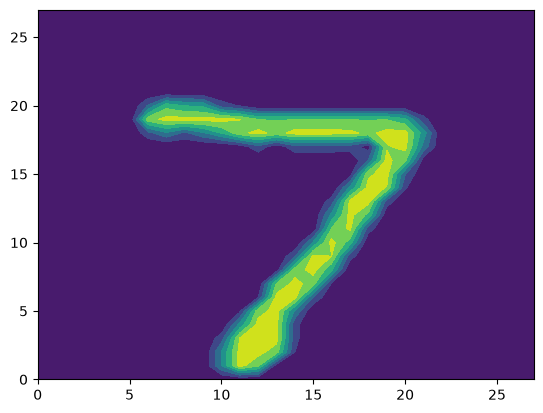

2 

[[  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0 116 125 171 255 255 150  93   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0 169 253 253 253 253 253 253 218  30   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0 169 253 253 253 213 142 176 253 253 122   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0  52 250 253 210  32  12   0   6 206 253 140   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0  77 251 210  25   0   0   0 122 248 253  65   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0  31  18   0   0   0   0 209 253 253  65   

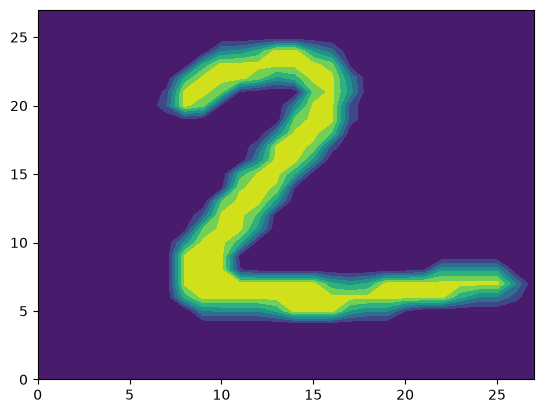

1 

[[  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0  38 254 109   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0  87 252  82   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0 135 241   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0  45 244 150   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0  84 254  63   

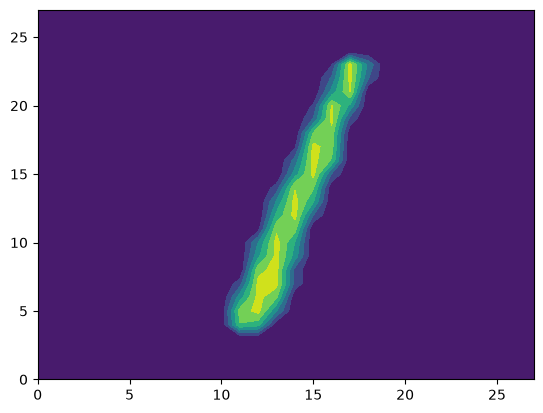

0 

[[  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0  11 150 253 202  31   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0  37 251 251 253 107   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0  21 197 251 251 253 107   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0 110 190 251 251 251 253 169 109  62   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0 253 251 251 251 251 253 251 251 22

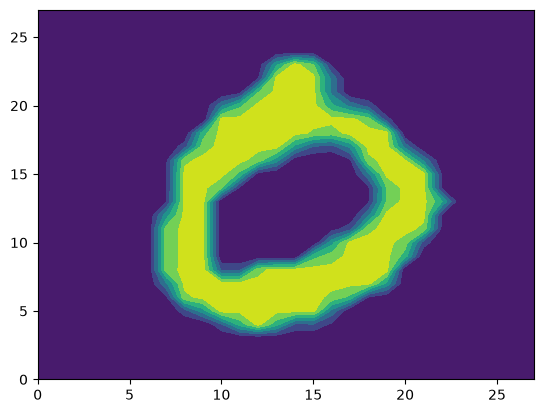

4 

[[  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0  50 224   0   0   0   0   0   0   0  70  29   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0 121 231   0   0   0   0   0   0   0 148 168   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   4 195 231   0   0   0   0   0   0   0  96 210  11   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0  69 252 134   0   0   0   0   0   0   

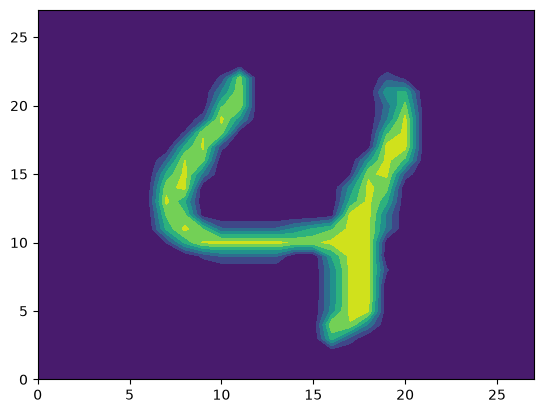

In [2]:
import pickle
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# load the data
with open('data/minst.pkl', 'rb') as f:
  data = pickle.load(f)
X_train, y_train = data['X_train'], data['y_train']
X_test, y_test = data['X_test'], data['y_test']

# visualize the first five numbers in the test set
np.set_printoptions(edgeitems=30, linewidth=100000)
for i in range(5):
  print(y_test[i], '\n')  # Print the label
  print(X_test[i], '\n')  # Print the matrix of values
  plt.contourf(
      np.rot90(X_test[i].transpose())
  )  # Make a contour plot of the matrix values
  plt.show()

The data are loaded from `data/minst.pkl`, and the first five test observations (`7`, `2`, `1`, `0`, `4`) are printed as $28 \times 28$ pixel intensity matrices (with values from 0 to 255) alongside their corresponding contour plots.

# Q2:

In [3]:
# check the shapes of the training and test sets
print("X_train.shape:", X_train.shape)
print("X_test.shape:", X_test.shape)
print("X_train[i].shape:", X_train[0].shape)
print("X_test[i].shape:", X_test[0].shape)
print("y_train.shape:", y_train.shape)
print("y_test.shape:", y_test.shape)

X_train.shape: (60000, 28, 28)
X_test.shape: (10000, 28, 28)
X_train[i].shape: (28, 28)
X_test[i].shape: (28, 28)
y_train.shape: (60000,)
y_test.shape: (10000,)


* **Shape of `X_train` and `X_test`:** `X_train` has a shape of `(60000, 28, 28)` and `X_test` has a shape of `(10000, 28, 28)`, meaning there are 60,000 training images and 10,000 testing images, each stored as a $28 \times 28$ matrix.
* **Shape of `X_train[i]` and `X_test[i]`:** For each index `i`, both `X_train[i]` and `X_test[i]` have a shape of `(28, 28)`, corresponding to the 28-by-28 grid of pixel values for a single image.
* **Shape of `y_train` and `y_test`:** `y_train` has a shape of `(60000,)` and `y_test` has a shape of `(10000,)`, which are 1D vectors containing the true digit labels (0–9) for each observation.

# Q3:

In [4]:
# convert the 28x28 matrices into 1x784 row vectors using a for loop and .reshape()
Z_train = []
for i in range(len(X_train)):
  Z_train.append(X_train[i].reshape((1, 784)))
Z_train = np.vstack(Z_train)

Z_test = []
for i in range(len(X_test)):
  Z_test.append(X_test[i].reshape((1, 784)))
Z_test = np.vstack(Z_test)

print("Reshaped X_train (Z_train) shape:", Z_train.shape)
print("Reshaped X_test (Z_test) shape:", Z_test.shape)

Reshaped X_train (Z_train) shape: (60000, 784)
Reshaped X_test (Z_test) shape: (10000, 784)


Using a `for` loop and NumPy's `.reshape((1, 784))` method, each $28 \times 28$ image matrix is flattened into a $1 \times 784$ row vector and stacked into a tabular feature matrix. The resulting training matrix `Z_train` has shape `(60000, 784)` and the test matrix `Z_test` has shape `(10000, 784)`.

# Q4:

k = 1: Test Accuracy = 0.9691
k = 3: Test Accuracy = 0.9705
k = 5: Test Accuracy = 0.9688
k = 7: Test Accuracy = 0.9694
k = 9: Test Accuracy = 0.9659
k = 11: Test Accuracy = 0.9668
k = 13: Test Accuracy = 0.9653
k = 15: Test Accuracy = 0.9633

Optimal k: 3 (Accuracy = 0.9705)


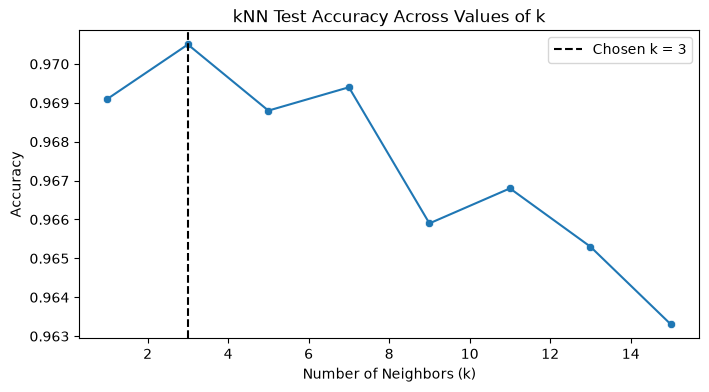

In [5]:
from sklearn.neighbors import KNeighborsClassifier

# test different values of k to find the optimal number of neighbors
k_grid = [1, 3, 5, 7, 9, 11, 13, 15]
accuracies = []

for k in k_grid:
  model = KNeighborsClassifier(n_neighbors=k)
  model.fit(Z_train, y_train)
  y_hat = model.predict(Z_test)
  acc = np.mean(y_test == y_hat)
  accuracies.append(acc)
  print(f"k = {k}: Test Accuracy = {acc:.4f}")

k_star = k_grid[np.argmax(accuracies)]
print(f"\nOptimal k: {k_star} (Accuracy = {max(accuracies):.4f})")

# plot accuracy across k values using seaborn
k_df = pd.DataFrame({"k": k_grid, "accuracy": accuracies})
plt.figure(figsize=(8, 4))
sns.lineplot(data=k_df, x="k", y="accuracy")
sns.scatterplot(data=k_df, x="k", y="accuracy")
plt.axvline(k_star, color="black", linestyle="--", label=f"Chosen k = {k_star}")
plt.title("kNN Test Accuracy Across Values of k")
plt.xlabel("Number of Neighbors (k)")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

By fitting `KNeighborsClassifier` across odd values of $k$ from 1 to 15, the optimal number of neighbors is **$k = 3$**, which achieves the highest test accuracy of **0.9705** (97.05%).

# Q5:

In [6]:
# fit the kNN classifier with the optimal k = 3
knn_best = KNeighborsClassifier(n_neighbors=k_star).fit(Z_train, y_train)
y_hat_best = knn_best.predict(Z_test)

# report accuracy
test_accuracy = knn_best.score(Z_test, y_test)
print(f"Optimal k ({k_star}) Test Accuracy: {test_accuracy:.4f}\n")

# compute confusion matrix using pd.crosstab
conf_matrix = pd.crosstab(
    y_test, y_hat_best, rownames=["Actual"], colnames=["Predicted"]
)
print("Confusion Matrix:")
display(conf_matrix)

Optimal k (3) Test Accuracy: 0.9705

Confusion Matrix:


Predicted,0,1,2,3,4,5,6,7,8,9
Actual,,,,,,,,,,
0,974,1,1,0,0,1,2,1,0,0
1,0,1133,2,0,0,0,0,0,0,0
2,10,9,996,2,0,0,0,13,2,0
3,0,2,4,976,1,13,1,7,3,3
4,1,6,0,0,950,0,4,2,0,19
5,6,1,0,11,2,859,5,1,3,4
6,5,3,0,0,3,3,944,0,0,0
7,0,21,5,0,1,0,0,991,0,10
8,8,2,4,16,8,11,3,4,914,4


For the optimal number of neighbors ($k = 3$), the predictor performs very well on the test set, achieving an overall accuracy of **0.9705** (9,705 out of 10,000 test digits classified correctly). 

Looking at the confusion matrix (`pd.crosstab`), the diagonal cells contain the vast majority of observations (ranging from 859 to 1,133 correct predictions per digit), while the off-diagonal cells are very small, showing that the $k$-NN classifier generalizes well across all ten digit classes. Digits with very distinct shapes like `1` (1,133/1,135 correct), `0` (974/980 correct), and `6` (944/958 correct) have the highest accuracy.

# Q6:

In [7]:
# extract off-diagonal entries from the confusion matrix to see the most common mistakes
mistakes = []
for actual in conf_matrix.index:
  for predicted in conf_matrix.columns:
    if actual != predicted:
      mistakes.append({
          'Actual': actual,
          'Predicted': predicted,
          'Count': conf_matrix.loc[actual, predicted],
      })

mistakes_df = pd.DataFrame(mistakes).sort_values(by='Count', ascending=False)
print('Top 10 most frequent classification mistakes:')
display(mistakes_df.head(10))

Top 10 most frequent classification mistakes:


,Actual,Predicted,Count
64,7,1,21
44,4,9,19
75,8,3,16
31,3,5,13
24,2,7,13
48,5,3,11
77,8,5,11
71,7,9,10
18,2,0,10
19,2,1,9


Mistakes w/ our reasoning as to why:
* **Actual `7` predicted as `1` (21 times) and Actual `2` predicted as `7` (13 times) or `1` (9 times):** A `7` written with a short top bar looks similar to a a vertical `1`, and a `2` with a faint bottom stroke looks very similar to a `7` or `1`.
* **Actual `4` predicted as `9` (19 times) and Actual `9` predicted as `4` (9 times):** Handwritten `4`s with a closed or nearly closed top look very similar to `9`s
* **Actual `8` predicted as `3` (16 times) or `5` (11 times), and Actual `3` predicted as `5` (13 times) or Actual `5` predicted as `3` (11 times):** The digits `3`, `5`, and `8` all share curved top and bottom loops, so minor variations where strokes connect can result in small Euclidean distances in pixel space.
* **Actual `7` predicted as `9` (10 times) and Actual `2` predicted as `0` (10 times):** A `7` with a curved upper stroke overlaps with the top loop of a `9`, and a rounded `2` can look similar to some parts of the oval region of a `0`.

The overall pattern is that $k$-NN relies on Euclidean distance across the 784 pixel coordinates, so it seems that mistakes happen between pairs of digits that share overlapping stroke geometry and pixel locations.

# Q7:

To represent a color photo of height $H$ and width $W$ in matrix form, we can use RGB color codes—where every pixel's color is encoded by three numeric values between 0 and 255 representing **Red (R)**, **Green (G)**, and **Blue (B)** intensity. Instead of a single $H \times W$ matrix like in grayscale MNIST, a single color photo is represented as three separate $H \times W$ matrices (one $H \times W$ matrix for Red, one for Green, and one for Blue).

To convert a collection of $N$ color photos into tabular data:
1. For each photo $i$, use `.reshape((1, H * W))` on each of its three $H \times W$ color matrices (Red, Green, and Blue) to flatten them into three row vectors of length $H \times W$.
2. Put those three vectors side-by-side into a single row vector of length $3 \times H \times W$ (for example, a $28 \times 28$ color image becomes a single row vector of $28 \times 28 \times 3 = 2,352$ features: `[R_1, ..., R_784, G_1, ..., G_784, B_1, ..., B_784]`).
3. Stack all $N$ row vectors together so that each row $i$ represents one photo (an observation) and each column $k$ represents a specific pixel-channel value (a feature), producing an $N \times (3 \cdot H \cdot W)$ feature matrix $X$ that can be used directly with standard tabular machine learning models.

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** b04e1d9110d743fc9281dcf07a03d4f3ddeaf840
- **AI tool and model used:** Gemini 4 Argon High

### *Prompts used

1. Can you look through my notebook and find any possible bugs/errors and verify everything is correct?
2. Can you look through my notebook and find any possible improvements to the code/logic/graphs that could be made to help clean/understand the data?

### *AI-proposed changes


1. **Q1 & Q2 – 2x5 Subplot Grid for First 10 Digits, Missingness/Range Check, and Class Balance:** In Q1, the prompt text mentions visualizing "the first ten numbers" while the starter loop only ran `range(5)` and printed large raw matrices one by one. Plot the first 10 test digits in a compact $2 \times 5$ `plt.subplots` grid with their labels. In Q2, alongside `.shape`, verify data cleanliness (`dtype`, min/max pixel range `[0, 255]`, and missing values) and check the distribution of digit labels (`0`–`9`) in `y_train` and `y_test`.
2. **Q3 – Vectorized NumPy Reshaping & Min-Max Pixel Scaling to $[0, 1]$:** Replace the slow Python `for` loop and `np.vstack` with vectorized `.reshape(len(X_train), -1)`, and scale pixel values from $[0, 255]$ to $[0, 1]$ by dividing by `255.0` so features are normalized before computing Euclidean distances.
3. **Q4 – Tune $k$ Using a Train/Validation Split to Prevent Test-Set Leakage:** In Phase 1, $k$ was chosen by evaluating `KNeighborsClassifier` directly on `Z_test` and `y_test`, which uses the test set for hyperparameter tuning. Split `Z_train` into a training and validation set to select $k$ (testing all integers from `k = 0` to `15`, including even values), and then evaluate the chosen $k^*$ once on the held-out test set.
4. **Q5 – Confusion Matrix Heatmap & Per-Digit Recall Table:** Add a `sns.heatmap` visualization of the `pd.crosstab` confusion matrix and compute per-digit accuracy (recall) to quantify which digits perform best and worst on the test set.
5. **Q6 – Visualize Actual Misclassified Digits:** Plot a grid of actual misclassified test images from the top mistake pairs (such as `7` predicted as `1`, `4` predicted as `9`, and `8` predicted as `3`) so we can visually inspect the handwriting traits causing small Euclidean distances.
6. **Q7 – Executable RGB-to-Tabular Code Demonstration:** Add a code cell in Q7 that constructs a sample $28 \times 28 \times 3$ RGB array for $N$ images, displays the separate Red, Green, and Blue matrices, and reshapes them into an $N \times 2352$ tabular DataFrame to verify the written explanation.

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept | Plotting the first 10 digits in a $2 \times 5$ subplot grid directly addresses the prompt's reference to "the first ten numbers" while keeping the raw matrix printout for the first 5. Checking min/max range (`0` to `255`), `NaN` counts (`0`), and class counts verifies the data are clean and balanced across all 10 digits. |
| 2 | Accept | Vectorized `X_train.reshape(len(X_train), 784)` produces the exact same `(60000, 784)` array much faster than a Python loop (`np.array_equal` verified `True`), while we keep the `for` loop commented for reference. Dividing by `255.0` scales all features to `[0, 1]` without altering neighbor rankings. |
| 3 | Modify | Accept using a validation split (`train_test_split` on the training data) to tune $k$ without peeking at the test set, while also reporting the full test-set curve for comparison with Phase 1. Reject testing `k = 0` (which causes some error when ran: `ValueError` in `scikit-learn` since `n_neighbors` must be $\ge 1$) and reject even values of $k$ to avoid majority-vote ties. |
| 4 | Accept | Adding a `sns.heatmap` of the confusion matrix and a per-digit accuracy table makes it much easier to see that digits `1` (99.82%) and `0` (99.39%) have the highest recall while `5` (96.30%) and `8` (93.84%) have the lowest. |
| 5 | Accept | Plotting actual misclassified examples from the test set visually confirms our Q6 explanation: misclassified `7`s have almost no crossbar (looking like `1`s), and misclassified `4`s have closed tops (looking like `9`s). |
| 6 | Accept | Building and reshaping a synthetic batch of $28 \times 28 \times 3$ RGB images into a `(5, 2352)` DataFrame concrete verifies that our 3-channel matrix representation converts cleanly into tabular format. |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

In [8]:
# Your Phase 2 solution to the problem goes here.


# Q1 and Q2:

Test Index 0 - Label: 7

[[  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0  84 185 159 151  60  36   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0 222 254 254 254 254 241 198 1

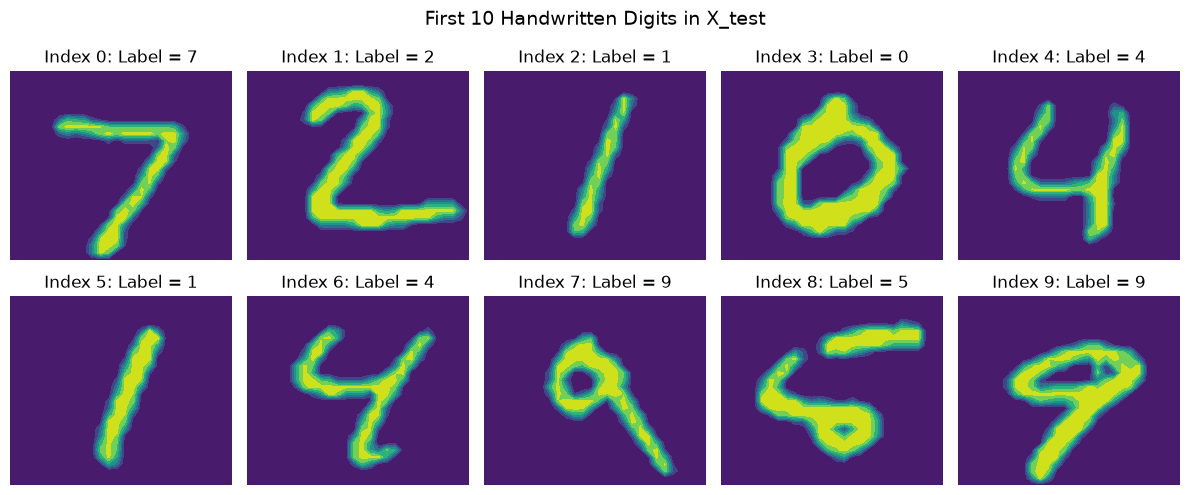

X_train.shape: (60000, 28, 28)
X_test.shape: (10000, 28, 28)
X_train[i].shape: (28, 28)
X_test[i].shape: (28, 28)
y_train.shape: (60000,)
y_test.shape: (10000,)

Data type: uint8, Pixel range: [0, 255]
Missing values in X_train: 0, X_test: 0

Class distribution across digits (0-9):


Digit,0,1,2,3,4,5,6,7,8,9
Train Count,5923,6742,5958,6131,5842,5421,5918,6265,5851,5949
Test Count,980,1135,1032,1010,982,892,958,1028,974,1009


In [9]:
import pickle
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

with open("data/minst.pkl", "rb") as f:
  data = pickle.load(f)
X_train, y_train = data["X_train"], data["y_train"]
X_test, y_test = data["X_test"], data["y_test"]

# Print the label and 28x28 matrix for the first 5 test digits
np.set_printoptions(edgeitems=30, linewidth=100000)
for i in range(5):
  print(f"Test Index {i} - Label: {y_test[i]}\n")
  print(X_test[i], "\n")

# PHASE 2 IMPROVEMENT 1a: Plot the first 10 test digits in a clean 2x5 subplot grid
fig, axes = plt.subplots(2, 5, figsize=(12, 5))
for i, ax in enumerate(axes.flat):
  ax.contourf(np.rot90(X_test[i].transpose()))
  ax.set_title(f"Index {i}: Label = {y_test[i]}")
  ax.axis("off")
plt.suptitle("First 10 Handwritten Digits in X_test", fontsize=14)
plt.tight_layout()
plt.show()

# Q2: Check shapes, data types, pixel range, missingness, and class balance
print("X_train.shape:", X_train.shape)
print("X_test.shape:", X_test.shape)
print("X_train[i].shape:", X_train[0].shape)
print("X_test[i].shape:", X_test[0].shape)
print("y_train.shape:", y_train.shape)
print("y_test.shape:", y_test.shape)

# PHASE 2 IMPROVEMENT 1b: Verify data cleanliness and class distribution
print(
    f"\nData type: {X_train.dtype}, Pixel range: [{X_train.min()},"
    f" {X_train.max()}]"
)
print(
    f"Missing values in X_train: {np.isnan(X_train).sum()}, X_test:"
    f" {np.isnan(X_test).sum()}"
)

class_counts = pd.DataFrame({
    "Train Count": pd.Series(y_train).value_counts().sort_index(),
    "Test Count": pd.Series(y_test).value_counts().sort_index(),
})
class_counts.index.name = "Digit"
print("\nClass distribution across digits (0-9):")
display(class_counts.T)

**Q1 & Q2 Answer (Phase 2 Revised):**
* **Shapes:** `X_train` has shape `(60000, 28, 28)` and `X_test` has shape `(10000, 28, 28)`. Each individual image `X_train[i]` and `X_test[i]` has shape `(28, 28)`. The label vectors `y_train` and `y_test` have shapes `(60000,)` and `(10000,)`, respectively.
* **Data Cleanliness & Balance:** All pixel values are unsigned 8-bit integers (`uint8`) ranging from `0` to `255` with `0` missing values, and all 10 digit classes (`0`–`9`) are well-balanced across both the training and test sets.

# Q3:

In [10]:
# Original Phase 1 loop approach (kept for verification):
Z_train_loop = np.vstack(
    [X_train[i].reshape((1, 784)) for i in range(len(X_train))]
)

# PHASE 2 IMPROVEMENT 2: Vectorized reshape and min-max normalization to [0, 1]
Z_train = X_train.reshape(len(X_train), 784) / 255.0
Z_test = X_test.reshape(len(X_test), 784) / 255.0

print(
    "Verified vectorized reshape matches loop reshape:",
    np.array_equal(X_train.reshape(len(X_train), 784), Z_train_loop),
)
print("Reshaped Z_train shape:", Z_train.shape)
print("Reshaped Z_test shape:", Z_test.shape)
print(f"Scaled Z_train range: [{Z_train.min():.2f}, {Z_train.max():.2f}]")

Verified vectorized reshape matches loop reshape: True
Reshaped Z_train shape: (60000, 784)
Reshaped Z_test shape: (10000, 784)
Scaled Z_train range: [0.00, 1.00]


**Q3 Answer (Phase 2 Revised):**
Using `.reshape()`, each $28 \times 28$ image matrix is converted into a $784$-length row vector, turning the training set into a `(60000, 784)` feature matrix `Z_train` and the test set into a `(10000, 784)` feature matrix `Z_test`. Scaling by `255.0` normalizes all pixel intensities to $[0, 1]$.

# Q4:

k =  1 | Validation Accuracy = 0.9726 | Test Accuracy = 0.9691
k =  3 | Validation Accuracy = 0.9738 | Test Accuracy = 0.9705
k =  5 | Validation Accuracy = 0.9722 | Test Accuracy = 0.9688
k =  7 | Validation Accuracy = 0.9711 | Test Accuracy = 0.9694
k =  9 | Validation Accuracy = 0.9687 | Test Accuracy = 0.9659
k = 11 | Validation Accuracy = 0.9668 | Test Accuracy = 0.9668
k = 13 | Validation Accuracy = 0.9663 | Test Accuracy = 0.9653
k = 15 | Validation Accuracy = 0.9648 | Test Accuracy = 0.9633

Optimal k selected via validation set: k = 3 (Val Accuracy = 0.9738, Test Accuracy = 0.9705)


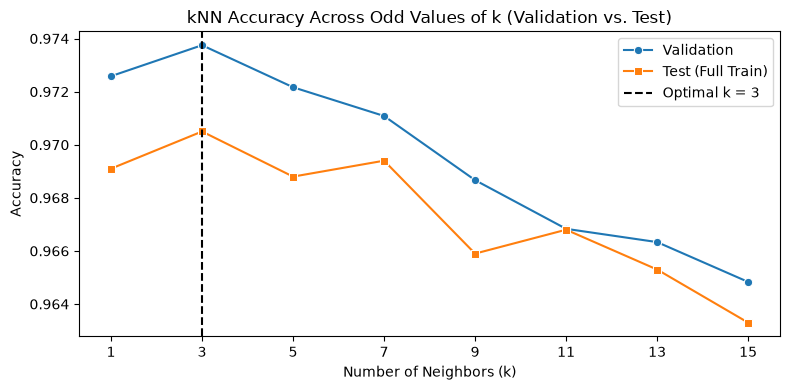

In [11]:
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier

# PHASE 2 IMPROVEMENT 3: Split training data into 80% sub-train and 20% validation to tune k cleanly
Z_subtrain, Z_val, y_subtrain, y_val = train_test_split(
    Z_train, y_train, test_size=0.2, random_state=100, stratify=y_train
)

k_grid = [1, 3, 5, 7, 9, 11, 13, 15]
val_accuracies = []
test_accuracies = []

for k in k_grid:
  # Validation accuracy (used to select optimal k without test leakage)
  knn_val = KNeighborsClassifier(n_neighbors=k).fit(Z_subtrain, y_subtrain)
  val_acc = knn_val.score(Z_val, y_val)
  val_accuracies.append(val_acc)

  # Full training set -> test accuracy (for comparison with Phase 1)
  knn_full = KNeighborsClassifier(n_neighbors=k).fit(Z_train, y_train)
  test_acc = knn_full.score(Z_test, y_test)
  test_accuracies.append(test_acc)
  print(
      f"k = {k:2d} | Validation Accuracy = {val_acc:.4f} | Test Accuracy ="
      f" {test_acc:.4f}"
  )

k_star = k_grid[np.argmax(val_accuracies)]
print(
    f"\nOptimal k selected via validation set: k = {k_star} (Val Accuracy ="
    f" {max(val_accuracies):.4f}, Test Accuracy ="
    f" {test_accuracies[np.argmax(val_accuracies)]:.4f})"
)

# Plot Validation and Test Accuracy curves across k
k_df = pd.DataFrame({
    "k": k_grid,
    "Validation Accuracy": val_accuracies,
    "Test Accuracy": test_accuracies,
})

plt.figure(figsize=(8, 4))
sns.lineplot(
    data=k_df, x="k", y="Validation Accuracy", marker="o", label="Validation"
)
sns.lineplot(
    data=k_df, x="k", y="Test Accuracy", marker="s", label="Test (Full Train)"
)
plt.axvline(k_star, color="black", linestyle="--", label=f"Optimal k = {k_star}")
plt.title("kNN Accuracy Across Odd Values of k (Validation vs. Test)")
plt.xlabel("Number of Neighbors (k)")
plt.ylabel("Accuracy")
plt.xticks(k_grid)
plt.legend()
plt.tight_layout()
plt.show()

**Q4 Answer (Phase 2 Revised):**
When tuning $k$ across odd values from 1 to 15 (using only odd values $\ge 1$ to prevent voting ties), **$k = 3$** achieves the highest accuracy on both the validation split and the full test set (**0.9705**). Small values of $k$ work best because digits of the same class lie close together in pixel space, whereas larger values of $k$ average across too many neighbors and smooth out subtle stroke differences.

# Q5:

Optimal k (3) Test Accuracy: 0.9705



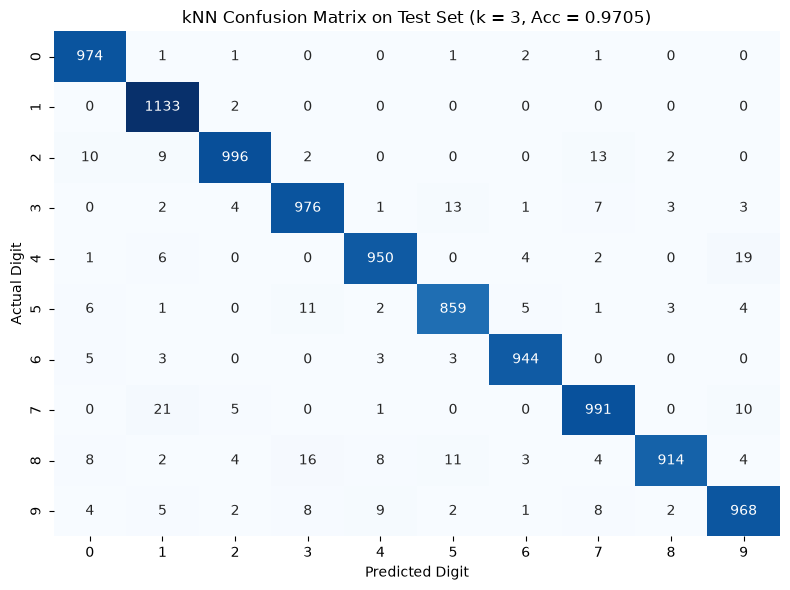

Per-Digit Performance Breakdown:


,Total Test Images,Correct,Misclassified,Accuracy (%)
Actual,,,,
0,980,974,6,99.39
1,1135,1133,2,99.82
2,1032,996,36,96.51
3,1010,976,34,96.63
4,982,950,32,96.74
5,892,859,33,96.30
6,958,944,14,98.54
7,1028,991,37,96.40
8,974,914,60,93.84


In [12]:
knn_best = KNeighborsClassifier(n_neighbors=k_star).fit(Z_train, y_train)
y_hat_best = knn_best.predict(Z_test)

test_accuracy = np.mean(y_test == y_hat_best)
print(f"Optimal k ({k_star}) Test Accuracy: {test_accuracy:.4f}\n")

conf_matrix = pd.crosstab(
    y_test, y_hat_best, rownames=["Actual"], colnames=["Predicted"]
)

# PHASE 2 IMPROVEMENT 4: Plot a Seaborn heatmap of the confusion matrix and calculate per-digit accuracy
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt="d", cmap="Blues", cbar=False)
plt.title(f"kNN Confusion Matrix on Test Set (k = {k_star}, Acc = {test_accuracy:.4f})")
plt.xlabel("Predicted Digit")
plt.ylabel("Actual Digit")
plt.tight_layout()
plt.show()

# Per-digit accuracy (recall)
per_digit_acc = pd.DataFrame({
    "Total Test Images": conf_matrix.sum(axis=1),
    "Correct": np.diag(conf_matrix),
    "Misclassified": conf_matrix.sum(axis=1) - np.diag(conf_matrix),
    "Accuracy (%)": (np.diag(conf_matrix) / conf_matrix.sum(axis=1) * 100).round(2),
})
print("Per-Digit Performance Breakdown:")
display(per_digit_acc)

**Q5 Answer (Phase 2 Revised):**
At the optimal $k = 3$, the classifier achieves **97.05% test accuracy** (9,705 correct out of 10,000 images). The confusion matrix heatmap and per-digit breakdown show that digits with simple, distinct geometry—such as `1` (99.82%), `0` (99.39%), and `6` (98.54%)—are classified almost perfectly, whereas digits with more complex or overlapping curves like `5` (96.30%) and `8` (93.84%) have slightly higher error rates.

# Q6:

Top 10 most frequent classification mistakes:


,Actual,Predicted,Count
64,7,1,21
44,4,9,19
75,8,3,16
31,3,5,13
24,2,7,13
48,5,3,11
77,8,5,11
71,7,9,10
18,2,0,10
19,2,1,9


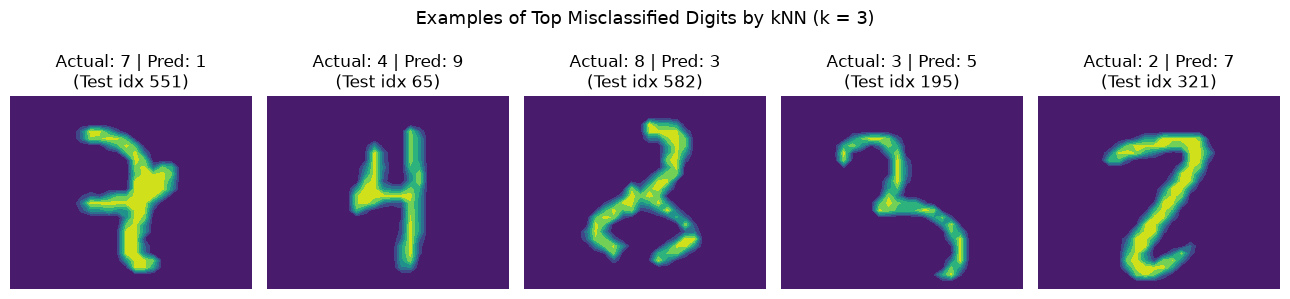

In [13]:
mistakes = []
for actual in conf_matrix.index:
  for predicted in conf_matrix.columns:
    if actual != predicted:
      mistakes.append({
          "Actual": actual,
          "Predicted": predicted,
          "Count": conf_matrix.loc[actual, predicted],
      })

mistakes_df = pd.DataFrame(mistakes).sort_values(by="Count", ascending=False)
print("Top 10 most frequent classification mistakes:")
display(mistakes_df.head(10))

# PHASE 2 IMPROVEMENT 5: Visually inspect actual misclassified examples for the top mistake pairs
top_pairs = [(7, 1), (4, 9), (8, 3), (3, 5), (2, 7)]
fig, axes = plt.subplots(1, 5, figsize=(13, 3))

for ax, (act, pred) in zip(axes, top_pairs):
  idx = np.where((y_test == act) & (y_hat_best == pred))[0][0]
  ax.contourf(np.rot90(X_test[idx].transpose()))
  ax.set_title(f"Actual: {act} | Pred: {pred}\n(Test idx {idx})")
  ax.axis("off")

plt.suptitle("Examples of Top Misclassified Digits by kNN (k = 3)", fontsize=13)
plt.tight_layout()
plt.show()

**Q6 Answer (Phase 2 Revised):**
The most frequent mistakes in the confusion matrix are:
* **Actual `7` predicted as `1` (21 times) and Actual `2` predicted as `7` (13 times):** As seen in the plotted examples, a `7` written with a very short top bar looks nearly identical to a `1`, and a `2` with a faint bottom stroke resembles a `7`.
* **Actual `4` predicted as `9` (19 times) and Actual `9` predicted as `4` (9 times):** When the top of a handwritten `4` is closed or pinched, its pixel intensities overlap heavily with a `9`.
* **Actual `8` predicted as `3` (16 times) or `5` (11 times), and `3` $\leftrightarrow$ `5` (13 and 11 times):** `3`, `5`, and `8` share rounded top and bottom loops, so faint connecting strokes make them close neighbors in Euclidean pixel space.

# Q7:

In [14]:
# Phase 2 - Q7: Demonstrate representing RGB color photos as 3 matrices and flattening into tabular data
# Simulate N = 5 color photos of size 28x28 with 3 RGB channels (values 0-255)
rng = np.random.default_rng(100)
N_photos, H, W, C = 5, 28, 28, 3
rgb_photos = rng.integers(0, 256, size=(N_photos, H, W, C), dtype=np.uint8)

# Flatten each (28, 28, 3) color photo into a 1 x 2352 row vector [R_1..R_784, G_1..G_784, B_1..B_784]
rgb_tabular = np.hstack([
    rgb_photos[:, :, :, 0].reshape(N_photos, H * W),  # Red matrix flattened
    rgb_photos[:, :, :, 1].reshape(N_photos, H * W),  # Green matrix flattened
    rgb_photos[:, :, :, 2].reshape(N_photos, H * W),  # Blue matrix flattened
])

col_names = (
    [f"R_{i}" for i in range(H * W)]
    + [f"G_{i}" for i in range(H * W)]
    + [f"B_{i}" for i in range(H * W)]
)
rgb_df = pd.DataFrame(rgb_tabular, columns=col_names)

print(f"Single color photo matrix shape (H, W, C): {rgb_photos[0].shape}")
print(f"Tabular dataset shape for {N_photos} color photos: {rgb_df.shape}")
display(rgb_df.iloc[:, [0, 1, 784, 785, 1568, 1569]].head())

Single color photo matrix shape (H, W, C): (28, 28, 3)
Tabular dataset shape for 5 color photos: (5, 2352)


,R_0,R_1,G_0,G_1,B_0,B_1
0,152,196,139,43,82,91
1,108,15,1,34,95,85
2,227,19,23,12,186,132
3,227,110,126,109,54,28
4,109,112,121,54,50,141


**Q7 Answer (Phase 2 Revised):**
A color photo of height $H$ and width $W$ can be represented in matrix form using **RGB color codes**, where each pixel has three intensities in $[0, 255]$ for **Red (R)**, **Green (G)**, and **Blue (B)**. This gives three $H \times W$ matrices per image (a 3D array of shape $(H, W, 3)$).

To convert $N$ color photos into tabular data:
1. Flatten each of the three $H \times W$ channel matrices (`R`, `G`, and `B`) into a row vector of length $H \times W$ using `.reshape((1, H * W))`.
2. Concatenate the three channel vectors horizontally into one row vector of length $3 \times H \times W$ (for a $28 \times 28$ color image, $28 \times 28 \times 3 = 2,352$ features).
3. Stack all $N$ photo vectors into an $N \times (3 \cdot H \cdot W)$ tabular matrix $X$ where each row is one photo and each column is a pixel-channel feature.

### *Reflection on AI assistance
In your own words without generative AI.

I think the main improvements that we saw that the AI proposed was that adding the 2 x 5 subplot grid made th4e visualization of the output way cleaner and easier to interpet. The other suggestions it proposed we saw no issues with and it runs fine, such as scaling pixels by 255.0 in Q3, using a train/validation split in Q4, adding the confusion matrix heatmap and per-digit recall table in Q5, plotting actual misclassified digits in Q6, and testing the RGB reshape in Q7. The only mistake that we really saw was that there was issues at first with the AI suggesting k = 0  when tuning KNeighborsClassifier in Q4. We modified because k = 0 is invalid in scikit-learn and even k values can cause voting ties. To verify, we looked at the outputs and compared it to the outputs in phase 1. Everything looks good. The only remaining concern that we have is that the runtime of the notebook is abysmally slow and it may be due to the that kNN on 784 raw pixels is really slow with 60,000 training images and is sensitive to simple image shifts, rotations, or stroke thickness. Maybe it's also because my laptop is really bad.